# VLM Evaluation - American Football Pre-Snap Understanding
**Models:** `qwen3-vl:30b`, `gemma3:27b`, `llama3.2-vision:11b` via Ollama  
**Phases:**
- **A** - Text-only football knowledge probing
- **B** - Basic image understanding (per image), plus an offense/defense "swap" analysis
- **C1** - Formation classification: baseline (options only)
- **C2** - Formation classification: with descriptions
- **C3** - Formation classification: with decision tree

## Setup

In [1]:
import base64
import json
import re
from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# ── Config ────────────────────────────────────────────────────────────────────
OLLAMA_URL  = "http://localhost:11434/api/chat"
MODELS      = ["qwen3-vl:30b", "gemma3:27b", "llama3.2-vision:11b"]
FORMATIONS  = ["TRIO", "EMPTY", "DOUBLES", "TREY", "TANK"]

ROOT        = Path(".")
MANIFEST    = ROOT / "Testset" / "manifest.csv"
IMAGE_DIR   = ROOT / "Testset" / "Presnap_Images"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

def model_slug(model: str) -> str:
    return model.replace(":", "_").replace("/", "_")

for m in MODELS:
    (RESULTS_DIR / model_slug(m)).mkdir(exist_ok=True)

print(f"Models : {MODELS}")
print(f"Images : {len(list(IMAGE_DIR.glob('*.jpg')))} found")

Models : ['qwen3-vl:30b', 'gemma3:27b', 'llama3.2-vision:11b']
Images : 40 found


In [2]:
# Load manifest
df = pd.read_csv(MANIFEST)

def manifest_to_image_path(row):
    video_path = Path(row["PATH"].lstrip("/"))
    game  = video_path.parent.name
    stem  = video_path.stem.replace(" ", "-")
    start = int(row["START"])
    return IMAGE_DIR / f"{game}_{stem}_t{start}.jpg"

df["image_path"]   = df.apply(manifest_to_image_path, axis=1)
df["image_exists"] = df["image_path"].apply(lambda p: p.exists())

# defined once here so any phase can be re-run
# independently without needing to re-trigger another phase first
valid_df = df[df["image_exists"]].reset_index(drop=True)

print(f"{df['image_exists'].sum()}/{len(df)} images found on disk")
print("\nFormation distribution:")
print(df["OFF_FORM"].value_counts())

40/40 images found on disk

Formation distribution:
OFF_FORM
TRIO       14
DOUBLES    11
EMPTY       5
TREY        5
TANK        5
Name: count, dtype: int64


In [3]:
# Ollama helpers

MODEL_MAX_TOKENS = {
    "qwen3-vl:30b":        8192,
    "gemma3:27b":          1024,
    "llama3.2-vision:11b": 1024,
}

def encode_image(image_path: Path) -> str:
    with open(image_path, "rb") as f:
        return base64.b64encode(f.read()).decode("utf-8")

def _stream_response(payload: dict) -> str:
    """Stream a response from Ollama and return the content."""
    with requests.post(OLLAMA_URL, json=payload, stream=True, timeout=300) as r:
        r.raise_for_status()
        content = ""
        for line in r.iter_lines():
            if line:
                chunk = json.loads(line)
                # collect content
                content += chunk.get("message", {}).get("content", "")
                if chunk.get("done"):
                    break
    return content.strip()

def ask_text(prompt: str, model: str, think: bool = False) -> str:
    payload = {
        "model": model,
        "think": think,
        "messages": [{"role": "user", "content": prompt}],
        "stream": True,
        "options": {
            "num_predict": MODEL_MAX_TOKENS.get(model, 1024),
            "temperature": 0,  # deterministic decoding, for reproducibility
        },
    }
    return _stream_response(payload)

def ask_image(prompt: str, image_path: Path, model: str, think: bool = False) -> str:
    payload = {
        "model": model,
        "think": think,
        "messages": [{
            "role": "user",
            "content": prompt,
            "images": [encode_image(image_path)],
        }],
        "stream": True,
        "options": {
            "num_predict": MODEL_MAX_TOKENS.get(model, 1024),
            "temperature": 0,  # deterministic decoding, for reproducibility
        },
    }
    return _stream_response(payload)

def extract_formation(raw: str) -> str:
    raw_upper = raw.upper()
    for f in FORMATIONS:
        if re.search(rf"\b{f}\b", raw_upper):
            return f
    return "UNKNOWN"

def save(data, path: Path):
    with open(path, "w") as f:
        json.dump(data, f, indent=2)

def load(path: Path):
    with open(path) as f:
        return json.load(f)

print("Helpers ready.")

Helpers ready.


In [4]:
# Preflight check

def check_models_available(models: list[str]) -> None:
    tags_url = OLLAMA_URL.replace("/api/chat", "/api/tags")
    try:
        resp = requests.get(tags_url, timeout=5)
        resp.raise_for_status()
    except requests.exceptions.RequestException as e:
        raise RuntimeError(
            f"Could not reach Ollama at {tags_url}. Is `ollama serve` running? ({e})"
        ) from e

    available = {m["name"] for m in resp.json().get("models", [])}
    missing = [m for m in models if m not in available]
    if missing:
        raise RuntimeError(
            f"Model(s) not found in Ollama: {missing}\n"
            f"Available: {sorted(available)}\n"
            f"Pull them first, e.g. `ollama pull {missing[0]}`"
        )
    print(f"All {len(models)} model(s) available: {models}")

check_models_available(MODELS)

All 3 model(s) available: ['qwen3-vl:30b', 'gemma3:27b', 'llama3.2-vision:11b']


---
## Phase A - Text-only Football Knowledge Probing
Sanity check: does each model understand these formations without images?

In [6]:
PHASE_A_PROMPTS = [
    {
        "id": "A1",
        "prompt": (
            """In American football, briefly explain what each of the following
            offensive pre-snap formations looks like:
            EMPTY, TRIO, DOUBLES, TREY, TANK."""
        ),
        "expected": None,
    },
    {
        "id": "A2",
        "prompt": (
            """In American football, which offensive pre-snap formation has NO running backs
            in the backfield?
            Choose from: EMPTY, TRIO, DOUBLES, TREY, TANK.
            Reply with the formation name only."""
        ),
        "expected": "EMPTY",
    },
    {
        "id": "A3",
        "prompt": (
            """In American football, which of the following formations uses tight ends or fullbacks?
            Choose two from: EMPTY, TRIO, DOUBLES, TREY, TANK.
            Reply with the formation names separated by an ","."""
        ),
        "expected": "TANK,TREY",
    },
    {
        "id": "A4",
        "prompt": (
            """In American football, which offensive pre-snap formation has three true Wide Receivers on one side?
            Choose from: EMPTY, TRIO, DOUBLES, TREY, TANK.
            Reply with the formation name only."""
        ),
        "expected": "TRIO",
    },
    {
        "id": "A5",
        "prompt": (
            """In American football, which offensive pre-snap formation has exactly two true Wide Receivers on each side?
            Choose from: EMPTY, TRIO, DOUBLES, TREY, TANK.
            Reply with the formation name only."""
        ),
        "expected": "DOUBLES",
    },
    {
        "id": "A6",
        "prompt": (
            """In American football, what is the key structural difference between
            the TRIO and TREY offensive formations? Answer in 2-3 sentences."""
        ),
        "expected": None,
    },
    {
        "id": "A7",
        "prompt": (
            """In American football, what is the key structural difference between
            the DOUBLES and TANK offensive formations? Answer in 2-3 sentences."""
        ),
        "expected": None,
    },
]

In [7]:
for model in MODELS:
    print(f"\n{'#'*60}")
    print(f"  MODEL: {model}")
    print(f"{'#'*60}")
    results = []
    for item in PHASE_A_PROMPTS:
        print(f"\n[{item['id']}] {item['prompt'][:80]}...")
        response = ask_text(item["prompt"], model)
        correct = None
        if item["expected"]:
            expected_terms = [t.strip() for t in item["expected"].upper().split(",")]
            correct = all(term in response.upper() for term in expected_terms)
            print(f"Expected: {item['expected']} | Correct: {correct}")
        print(f"Response:\n{response}")
        results.append({"id": item["id"], "response": response, "correct": correct})
    save(results, RESULTS_DIR / model_slug(model) / "phase_a.json")
    print(f"\n[{model}] Phase A saved.")

Response:
In American football, the key structural difference between the DOUBLES and TANK offensive formations is the alignment of the tight ends. In the DOUBLES formation, the tight ends line up on either side of the tackles, while in the TANK formation, the tight ends line up on the strong side of the formation, often with a fullback or extra tight end. This difference affects the blocking scheme and play-action possibilities.

[llama3.2-vision:11b] Phase A saved.


---
## Phase B - Basic Image Understanding
Can each model parse the visual content of a pre-snap image correctly?

In [19]:
PHASE_B_PROMPT = """Look at this pre-snap American football image and answer the following questions.
Give a short, direct answer for each question.

1. What is the jersey color of the OFFENSIVE team (the team at the line of scrimmage about to snap the ball)?
2. What is the jersey color of the DEFENSIVE team?
3. What is the helmet color of the OFFENSIVE team?
4. What is the helmet color of the DEFENSIVE team?
5. What is the pants color of the OFFENSIVE team?
6. What is the pants color of the DEFENSIVE team?
7. On which side of the image is the offense lined up - left or right?
8. At which yard line is the line of scrimmage approximately located? Give a number between 0 and 50.
9. How many players can you see on the offensive side?
10. How many wide receivers (players split wide from the main group) can you count?
11. Is there a running back visible in the offensive backfield?
12. Analyze the position of the QB relative to the hash marks. Is he closer to the near sideline, the far sideline or inbetween?

Format your answer exactly as:
1. Offensive jersey color: ...
2. Defensive jersey color: ...
3. Offensive helmet color: ...
4. Defensive helmet color: ...
5. Offensive pants color: ...
6. Defensive pants color: ...
7. Offense side: ...
8. Yard line: ...
9. Offensive players visible: ...
10. Wide receivers: ...
11. Running back visible: ...
12. QB position: ...
"""

In [20]:
for model in MODELS:
    print(f"\n{'#'*60}")
    print(f"  MODEL: {model}")
    print(f"{'#'*60}")
    results = []
    for i, row in valid_df.iterrows():
        img_path = row["image_path"]
        print(f"  [B {i+1}/{len(valid_df)}] {img_path.name}")
        response = ask_image(PHASE_B_PROMPT, img_path, model)
        results.append({
            "image":        img_path.name,
            "off_form_gt":  row["OFF_FORM"],
            "off_color_gt": row["OFF_COLOR_JERSEY"],
            "def_color_gt": row["DEF_COLOR_JERSEY"],
            "response":     response,
        })
    save(results, RESULTS_DIR / model_slug(model) / "phase_b.json")
    print(f"[{model}] Phase B saved.")

[llama3.2-vision:11b] Phase B saved.


In [8]:
# Phase B1 evaluation

def parse_phase_b(response: str) -> dict:
    """Extract numbered answers from the model response."""
    fields = {
        1: "off_jersey", 2: "def_jersey",
        3: "off_helmet", 4: "def_helmet",
        5: "off_pants",  6: "def_pants",
        7: "off_side",   8: "yard_line",
        9: "off_players", 10: "wide_receivers",
        11: "rb_visible", 12: "qb_position",
    }
    parsed = {}
    for n, key in fields.items():
        match = re.search(rf"^{n}.\s.*?:\s*(.+)$", response, re.MULTILINE | re.IGNORECASE)
        parsed[key] = match.group(1).strip() if match else ""
    return parsed

def expected_qb_position(off_side: str, hash_pos: str) -> str:
    """Derive expected QB position label from ground truth offense side and hash."""
    if hash_pos == "M":
        return "inbetween"
    if off_side == "L" and hash_pos == "R":
        return "near"
    if off_side == "L" and hash_pos == "L":
        return "far"
    if off_side == "R" and hash_pos == "L":
        return "near"
    if off_side == "R" and hash_pos == "R":
        return "far"
    return ""

# Ground truth for wide-receiver count and RB-in-backfield is not a separate
# manifest column, but both are fully determined by the formation label itself
WR_COUNT_GT = {"EMPTY": 5, "TRIO": 4, "DOUBLES": 4, "TREY": 3, "TANK": 3}
RB_VISIBLE_GT = {"EMPTY": False, "TRIO": True, "DOUBLES": True, "TREY": True, "TANK": True}

def color_correct(predicted: str, ground_truth: str) -> bool:
    return ground_truth.lower() in predicted.lower()

def side_correct(predicted: str, ground_truth: str) -> bool:
    p = predicted.lower()
    if ground_truth.lower() == "l":
        return "left" in p
    if ground_truth.lower() == "r":
        return "right" in p
    return False

def yard_correct(predicted: str, ground_truth: int, tolerance: int = 5) -> bool:
    nums = re.findall(r"\d+", predicted)
    if not nums:
        return False
    return abs(int(nums[0]) - ground_truth) <= tolerance

def qb_pos_correct(predicted: str, expected: str) -> bool:
    p = predicted.lower()
    if expected == "near":
        return "near" in p
    if expected == "far":
        return "far" in p
    if expected == "inbetween":
        return "inbetween" in p or "between" in p or "middle" in p or "center" in p
    return False

def wr_count_correct(predicted: str, ground_truth: int) -> bool:
    nums = re.findall(r"\d+", predicted)
    return bool(nums) and int(nums[0]) == ground_truth

def rb_visible_correct(predicted: str, ground_truth: bool) -> bool:
    p = predicted.lower()
    has_yes = bool(re.search(r"\byes\b", p))
    has_no = bool(re.search(r"\bno\b", p))
    if ground_truth:
        return has_yes and not has_no
    return has_no and not has_yes

# ── Run evaluation ─────────────────────────────────────────────────────────────
# All metrics evaluated unconditionally on all 40 images.
phase_b_eval = []

for model in MODELS:
    path = RESULTS_DIR / model_slug(model) / "phase_b.json"
    if not path.exists():
        print(f"[MISSING] {path}")
        continue
    results = load(path)

    for res, (_, row) in zip(results, valid_df.iterrows()):
        p = parse_phase_b(res["response"])
        exp_qb = expected_qb_position(row["OFF_SIDE"], row["HASH"])
        gt_wr = WR_COUNT_GT[row["OFF_FORM"]]
        gt_rb = RB_VISIBLE_GT[row["OFF_FORM"]]

        phase_b_eval.append({
            "model":           model,
            "image":           res["image"],
            "game":            res["image"].split("_")[0],
            "empty_response":  res["response"].strip() == "",
            "off_side":        side_correct(p["off_side"],   row["OFF_SIDE"]),
            "yard_line":       yard_correct(p["yard_line"],  row["YARD_LN"]),
            "off_jersey":      color_correct(p["off_jersey"], row["OFF_COLOR_JERSEY"]),
            "def_jersey":      color_correct(p["def_jersey"], row["DEF_COLOR_JERSEY"]),
            "off_helmet":      color_correct(p["off_helmet"], row["OFF_COLOR_HELMET"]),
            "def_helmet":      color_correct(p["def_helmet"], row["DEF_COLOR_HELMET"]),
            "off_pants":       color_correct(p["off_pants"],  row["OFF_COLOR_PANTS"]),
            "def_pants":       color_correct(p["def_pants"],  row["DEF_COLOR_PANTS"]),
            "off_players_raw": p["off_players"],
            "wide_receivers":  wr_count_correct(p["wide_receivers"], gt_wr),
            "wide_receivers_raw": p["wide_receivers"],
            "rb_visible":      rb_visible_correct(p["rb_visible"], gt_rb),
            "rb_visible_raw":  p["rb_visible"],
            "qb_position":     qb_pos_correct(p["qb_position"], exp_qb),
        })

save(phase_b_eval, RESULTS_DIR / "phase_b_eval.json")

# ── Summary table ──────────────────────────────────────────────────────────────
metrics = ["off_side", "yard_line", "wide_receivers", "rb_visible", "qb_position",
           "off_jersey", "def_jersey", "off_helmet", "def_helmet", "off_pants", "def_pants"]

rows = []
for model in MODELS:
    subset = [e for e in phase_b_eval if e["model"] == model]
    n_side_ok = sum(e["off_side"] for e in subset)
    row = {"Model": model, "side correct": f"{n_side_ok}/40"}
    for m in metrics:
        vals = [e[m] for e in subset if e[m] is not None]
        row[m] = f"{sum(vals)/len(vals):.0%}" if vals else "N/A"
    rows.append(row)

eval_df = pd.DataFrame(rows).set_index("Model")
print(eval_df.to_string())

# Empty-response diagnostic
eval_raw_df = pd.DataFrame(phase_b_eval)
print("\nEmpty-response rate by model x game (%):")
print((eval_raw_df.groupby(["model", "game"])["empty_response"].mean() * 100)
      .round(0).unstack().to_string())

# Offensive-players-visible -> always 11 players on field
print("\nOffensive-players-visible answer distribution by model:")
for model in MODELS:
    vals = eval_raw_df.loc[eval_raw_df["model"] == model, "off_players_raw"]
    vals = vals.replace("", "(unparsed/empty)").str.rstrip(".")
    print(f"  {model}: {vals.value_counts().to_dict()}")

# Wide-receiver-count
print("\nWide-receiver-count answer distribution by model:")
for model in MODELS:
    vals = eval_raw_df.loc[eval_raw_df["model"] == model, "wide_receivers_raw"]
    vals = vals.replace("", "(unparsed/empty)").str.rstrip(".")
    print(f"  {model}: {vals.value_counts().to_dict()}")

# RB-visible
print("\nRB-visible answer distribution by model:")
for model in MODELS:
    vals = eval_raw_df.loc[eval_raw_df["model"] == model, "rb_visible_raw"]
    vals = vals.replace("", "(unparsed/empty)").str.rstrip(".")
    print(f"  {model}: {vals.value_counts().to_dict()}")

# Per-game accuracy breakdown
# Games 1 & 3 were filmed from a close sideline angle, Games 2 & 4 from a wider,
# more elevated angle: checking whether camera setup affects accuracy or the empty-response rate above.
print("\nPer-game accuracy by model (%):")
for m in ["off_side", "yard_line", "off_jersey", "def_jersey"]:
    print(f"\n{m}:")
    print((eval_raw_df.groupby(["model", "game"])[m].mean() * 100).round(0).unstack().to_string())

eval_df


,side correct,off_side,yard_line,wide_receivers,rb_visible,qb_position,off_jersey,def_jersey,off_helmet,def_helmet,off_pants,def_pants
Model,,,,,,,,,,,,
qwen3-vl:30b,20/40,50%,25%,0%,45%,18%,38%,28%,20%,30%,38%,28%
gemma3:27b,18/40,45%,28%,25%,88%,20%,28%,18%,25%,48%,45%,32%
llama3.2-vision:11b,20/40,50%,32%,15%,12%,20%,38%,20%,40%,35%,48%,32%


### Phase B2 - Image Understanding with Offense Side Provided

In [23]:
def make_phase_b2_prompt(off_side: str) -> str:
    side_str = "LEFT" if off_side == "L" else "RIGHT"
    return f"""Look at this pre-snap American football image and answer the following questions.
The offense (the team about to snap the ball) is lined up on the {side_str} side of the image.
Give a short, direct answer for each question.

1. What is the jersey color of the OFFENSIVE team?
2. What is the jersey color of the DEFENSIVE team?
3. What is the helmet color of the OFFENSIVE team?
4. What is the helmet color of the DEFENSIVE team?
5. What is the pants color of the OFFENSIVE team?
6. What is the pants color of the DEFENSIVE team?
7. At which yard line is the line of scrimmage approximately located? Give a number between 0 and 50.
8. How many players can you see on the offensive side?
9. How many wide receivers (players split wide from the main group) can you count?
10. Is there a running back visible in the offensive backfield?
11. Analyze the position of the QB relative to the hash marks. Is he closer to the near sideline, the far sideline or inbetween?

Format your answer exactly as:
1. Offensive jersey color: ...
2. Defensive jersey color: ...
3. Offensive helmet color: ...
4. Defensive helmet color: ...
5. Offensive pants color: ...
6. Defensive pants color: ...
7. Yard line: ...
8. Offensive players visible: ...
9. Wide receivers: ...
10. Running back visible: ...
11. QB position: ...
"""

# Run Phase B2
for model in MODELS:
    print(f"\n{'#'*60}\n  MODEL: {model}\n{'#'*60}")
    results = []
    for i, (_, row) in enumerate(valid_df.iterrows()):
        img_path = row["image_path"]
        print(f"  [B2 {i+1}/{len(valid_df)}] {img_path.name}")
        prompt   = make_phase_b2_prompt(row["OFF_SIDE"])
        response = ask_image(prompt, img_path, model)
        results.append({
            "image":        img_path.name,
            "off_form_gt":  row["OFF_FORM"],
            "off_side_gt":  row["OFF_SIDE"],
            "off_color_gt": row["OFF_COLOR_JERSEY"],
            "def_color_gt": row["DEF_COLOR_JERSEY"],
            "response":     response,
        })
    save(results, RESULTS_DIR / model_slug(model) / "phase_b2.json")
    print(f"[{model}] Phase B2 saved.")

[llama3.2-vision:11b] Phase B2 saved.


In [6]:
def parse_phase_b2(response: str) -> dict:
    """Extract numbered answers from the B2 response (11 questions, no offense side)."""
    fields = {
        1: "off_jersey", 2: "def_jersey",
        3: "off_helmet", 4: "def_helmet",
        5: "off_pants",  6: "def_pants",
        7: "yard_line",  8: "off_players",
        9: "wide_receivers", 10: "rb_visible",
        11: "qb_position",
    }
    parsed = {}
    for n, key in fields.items():
        match = re.search(rf"^{n}\.\s.*?:\s*(.+)$", response, re.MULTILINE | re.IGNORECASE)
        parsed[key] = match.group(1).strip() if match else ""
    return parsed

# Evaluate B2
phase_b2_eval = []

for model in MODELS:
    path = RESULTS_DIR / model_slug(model) / "phase_b2.json"
    if not path.exists():
        print(f"[MISSING] {path}")
        continue
    results = load(path)

    for res, (_, row) in zip(results, valid_df.iterrows()):
        p      = parse_phase_b2(res["response"])
        exp_qb = expected_qb_position(row["OFF_SIDE"], row["HASH"])

        phase_b2_eval.append({
            "model":       model,
            "image":       res["image"],
            "off_jersey":  color_correct(p["off_jersey"], row["OFF_COLOR_JERSEY"]),
            "def_jersey":  color_correct(p["def_jersey"], row["DEF_COLOR_JERSEY"]),
            "off_helmet":  color_correct(p["off_helmet"], row["OFF_COLOR_HELMET"]),
            "def_helmet":  color_correct(p["def_helmet"], row["DEF_COLOR_HELMET"]),
            "off_pants":   color_correct(p["off_pants"],  row["OFF_COLOR_PANTS"]),
            "def_pants":   color_correct(p["def_pants"],  row["DEF_COLOR_PANTS"]),
            "yard_line":   yard_correct(p["yard_line"],   row["YARD_LN"]),
            "qb_position": qb_pos_correct(p["qb_position"], exp_qb),
        })

save(phase_b2_eval, RESULTS_DIR / "phase_b2_eval.json")

# Comparison table: B vs B2
# Both phases evaluated on all 40 images unconditionally.
compare_metrics = ["off_jersey", "def_jersey", "off_helmet", "def_helmet",
                   "off_pants", "def_pants", "qb_position"]

rows = []
for model in MODELS:
    b1 = [e for e in phase_b_eval  if e["model"] == model]
    b2 = [e for e in phase_b2_eval if e["model"] == model]
    for m in compare_metrics:
        v1 = [e[m] for e in b1 if e[m] is not None]
        v2 = [e[m] for e in b2 if e[m] is not None]
        rows.append({
            "Model":  model,
            "Metric": m,
            "B (side inferred)": f"{sum(v1)/len(v1):.0%}" if v1 else "N/A",
            "B2 (side given)":   f"{sum(v2)/len(v2):.0%}" if v2 else "N/A",
        })

compare_df = pd.DataFrame(rows)
print(compare_df.to_string(index=False))

              Model      Metric B (side inferred) B2 (side given)
       qwen3-vl:30b  off_jersey               38%             28%
       qwen3-vl:30b  def_jersey               28%             15%
       qwen3-vl:30b  off_helmet               20%             20%
       qwen3-vl:30b  def_helmet               30%             20%
       qwen3-vl:30b   off_pants               38%             28%
       qwen3-vl:30b   def_pants               28%             10%
       qwen3-vl:30b qb_position               18%             10%
         gemma3:27b  off_jersey               28%             25%
         gemma3:27b  def_jersey               18%             12%
         gemma3:27b  off_helmet               25%             22%
         gemma3:27b  def_helmet               48%             28%
         gemma3:27b   off_pants               45%             38%
         gemma3:27b   def_pants               32%             28%
         gemma3:27b qb_position               20%             20%
llama3.2-v

In [9]:
# Offense/Defense "swap" analysis
# For every offensive-jersey-colour error, check whether the model actually named
# the DEFENSE's true colour instead of the offense's

def swap_analysis(phase_file: str, parse_fn) -> pd.DataFrame:
    rows = []
    for model in MODELS:
        path = RESULTS_DIR / model_slug(model) / phase_file
        if not path.exists():
            print(f"[MISSING] {path}")
            continue
        data = load(path)
        correct = swapped = other = 0
        for row in data:
            p = parse_fn(row["response"])
            off_gt, def_gt = row["off_color_gt"], row["def_color_gt"]
            pred_off = p["off_jersey"]
            if color_correct(pred_off, off_gt):
                correct += 1
            elif color_correct(pred_off, def_gt):
                swapped += 1
            else:
                other += 1
        rows.append({"Model": model, "Correct": correct, "Swapped": swapped, "Other wrong": other})
    return pd.DataFrame(rows).set_index("Model")

print("Phase B (offense side inferred by the model):")
swap_b = swap_analysis("phase_b.json", parse_phase_b)
print(swap_b.to_string())

print("\nPhase B2 (offense side given explicitly in the prompt):")
swap_b2 = swap_analysis("phase_b2.json", parse_phase_b2)
print(swap_b2.to_string())

for label, swap_df in [("B", swap_b), ("B2", swap_b2)]:
    errors = (swap_df["Swapped"] + swap_df["Other wrong"]).sum()
    swaps  = swap_df["Swapped"].sum()
    if errors:
        print(f"\nAcross all models, Phase {label}: {swaps}/{errors} ({swaps/errors:.0%}) "
              f"of offensive-jersey errors are literal offense/defense swaps.")

Phase B (offense side inferred by the model):
                     Correct  Swapped  Other wrong
Model                                             
qwen3-vl:30b              15       11           14
gemma3:27b                11       19           10
llama3.2-vision:11b       15       21            4

Phase B2 (offense side given explicitly in the prompt):
                     Correct  Swapped  Other wrong
Model                                             
qwen3-vl:30b              11        5           24
gemma3:27b                10       20           10
llama3.2-vision:11b       17       19            4

Across all models, Phase B: 51/79 (65%) of offensive-jersey errors are literal offense/defense swaps.

Across all models, Phase B2: 44/82 (54%) of offensive-jersey errors are literal offense/defense swaps.


---
## Phase C - Formation Classification
### Prompts

In [25]:
FORMATION_DESCRIPTIONS = {
    "EMPTY": (
        """EMPTY: No running backs or full backs in the backfield.
        The quarterback stands alone behind the offensive line.
        Typically 5 wide receivers spread across the field."""
    ),
    "TRIO": (
        """TRIO: Three wide receivers aligned on the same side of the field,
        with one wide receiver on the opposite side.
        Includes a running back in the backfield."""
    ),
    "DOUBLES": (
        """DOUBLES: Two wide receivers on each side of the field (balanced).
        Includes a running back in the backfield."""
    ),
    "TREY": (
        """TREY: Two wide receivers on one side, additionally on this side a full back or tight end
        aligned close to or behind the offensive line. On the other side a single wide receiver.
        Similar to TRIO but with a TE/FB on the three receiver side."""
    ),
    "TANK": (
        """TANK: On the single wide receiver side there is a TE/FB aligned close to or behind the offensive line.
        On the other side there are two wide receivers.
        Similar to DOUBLES but with a TE/FB on one of the two receiver sides."""
    ),
}

DECISION_TREE = """
Follow this step-by-step decision tree:

Step 1 - Is the backfield empty (no running backs or fullbacks behind the line of scrimmage)?
  YES: Formation is EMPTY. Done.
  NO:  Continue to Step 2.

Step 2 - Are there 2 wide receivers on each side (balanced, no TE/FB on either side)?
  YES: Formation is DOUBLES. Done.
  NO: Continue to Step 3.

Step 3 - Are there 3 pure wide receivers on the strong side and 1 WR on the weak side (no TE/FB on either side)?
  YES: Formation is TRIO. Done.
  NO: There are 2 WRs on the strong side and 1 WR on the weak side, plus a TE/FB somewhere. Continue to Step 4.

Step 4 - Where is the TE or FB aligned?
  TE/FB is on the STRONG side (the side with 2 WRs): Formation is TREY. Done.
  TE/FB is on the WEAK side (the side with 1 WR): Formation is TANK. Done.
"""


_base = (
    "Analyze this pre-snap American football image. "
    "The offense is the team lined up at the line of scrimmage about to snap the ball."
)
_options = f"Choose exactly one from: {', '.join(FORMATIONS)}.\n\nReply with the formation name ONLY - no explanation."

PHASE_C1_PROMPT = f"{_base}\n\nWhat is the offensive formation?\n{_options}"

PHASE_C2_PROMPT = (
    f"{_base}\n\nHere are the possible formations:\n"
    + "\n".join(f"- {FORMATION_DESCRIPTIONS[f]}" for f in FORMATIONS)
    + f"\n\nWhat is the offensive formation? {_options}"
)

PHASE_C3_PROMPT = (
    f"{_base}\n"
    + DECISION_TREE
    + f"\n{_options}"
)



PHASE_C_IDS = ["C1", "C2", "C3"]
PHASE_C_PROMPTS = {
    "C1": PHASE_C1_PROMPT, "C2": PHASE_C2_PROMPT,
    "C3": PHASE_C3_PROMPT,
}
print("Phase C prompts defined:", PHASE_C_IDS)

Phase C prompts defined: ['C1', 'C2', 'C3']


### C1 - Baseline (options only)

In [26]:
def run_phase_c(phase_id: str, prompt: str, model: str, df_valid: pd.DataFrame) -> list:
    results = []
    for i, row in df_valid.iterrows():
        img_path = row["image_path"]
        print(f"  [{phase_id} {i+1}/{len(df_valid)}] {img_path.name}", end=" ... ")
        raw = ask_image(prompt, img_path, model)
        predicted = extract_formation(raw)
        correct = predicted == row["OFF_FORM"]
        print(f"GT={row['OFF_FORM']} | Pred={predicted} | {'✓' if correct else '✗'}")
        results.append({
            "phase":        phase_id,
            "model":        model,
            "image":        img_path.name,
            "ground_truth": row["OFF_FORM"],
            "raw_response": raw,
            "predicted":    predicted,
            "correct":      correct,
        })
    return results

In [11]:
for model in MODELS:
    print(f"\n{'#'*60}\n  MODEL: {model}\n{'#'*60}")
    results = run_phase_c("C1", PHASE_C1_PROMPT, model, valid_df)
    save(results, RESULTS_DIR / model_slug(model) / "phase_c1.json")
    acc = sum(r["correct"] for r in results) / len(results)
    print(f"  [{model}] C1 accuracy: {acc:.0%}")


############################################################
  MODEL: qwen3-vl:30b
############################################################


NameError: name 'run_phase_c' is not defined

### C2 - With descriptions

In [29]:
for model in MODELS:
    print(f"\n{'#'*60}\n  MODEL: {model}\n{'#'*60}")
    results = run_phase_c("C2", PHASE_C2_PROMPT, model, valid_df)
    save(results, RESULTS_DIR / model_slug(model) / "phase_c2.json")
    acc = sum(r["correct"] for r in results) / len(results)
    print(f"  [{model}] C2 accuracy: {acc:.0%}")

GT=TANK | Pred=TREY | ✗
  [llama3.2-vision:11b] C2 accuracy: 12%


### C3 - With decision tree

In [30]:
for model in MODELS:
    print(f"\n{'#'*60}\n  MODEL: {model}\n{'#'*60}")
    results = run_phase_c("C3", PHASE_C3_PROMPT, model, valid_df)
    save(results, RESULTS_DIR / model_slug(model) / "phase_c3.json")
    acc = sum(r["correct"] for r in results) / len(results)
    print(f"  [{model}] C3 accuracy: {acc:.0%}")

GT=TANK | Pred=TANK | ✓
  [llama3.2-vision:11b] C3 accuracy: 20%


---
## Evaluation & Results
Run from here if you just want to re-generate charts from saved results.

In [27]:
# Reload all results
all_results = {}  # all_results[model][phase] = list of dicts
for model in MODELS:
    all_results[model] = {}
    for phase in PHASE_C_IDS:
        path = RESULTS_DIR / model_slug(model) / f"phase_{phase.lower()}.json"
        if path.exists():
            all_results[model][phase] = load(path)
        else:
            print(f"[MISSING] {path}")

print("Results loaded.")

Results loaded.


In [28]:
# Accuracy table: models × phases
rows = []
for model in MODELS:
    for phase in PHASE_C_IDS:
        results = all_results[model].get(phase, [])
        if not results:
            continue
        total   = len(results)
        correct = sum(r["correct"] for r in results)
        unknown = sum(r["predicted"] == "UNKNOWN" for r in results)
        acc     = correct / total
        # Binomial standard error and 95% CI: with n=40, point-estimate
        # differences between models/phases can easily be within noise.
        se      = (acc * (1 - acc) / total) ** 0.5
        ci95    = 1.96 * se
        rows.append({"Model": model, "Phase": phase,
                     "Accuracy": acc,
                     "Correct": correct, "Total": total, "UNKNOWN": unknown,
                     "SE": se, "95% CI": f"±{ci95:.0%}"})

summary_df = pd.DataFrame(rows)
pivot = summary_df.pivot(index="Model", columns="Phase", values="Accuracy")

print("Accuracy with 95% confidence interval (binomial approximation, n=40 per cell):")
display_df = summary_df.copy()
display_df["Accuracy"] = display_df.apply(lambda r: f"{r['Accuracy']:.1%} {r['95% CI']}", axis=1)
print(display_df[["Model", "Phase", "Accuracy", "Correct", "Total", "UNKNOWN"]].to_string(index=False))
pivot

Phase,C1,C2,C3
Model,,,
gemma3:27b,0.150,0.375,0.125
llama3.2-vision:11b,0.125,0.125,0.200
qwen3-vl:30b,0.100,0.300,0.275


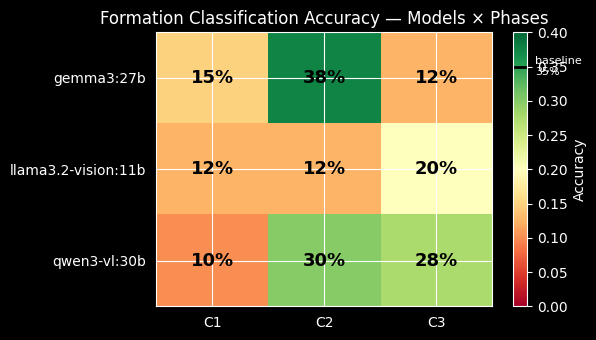

In [29]:
# Accuracy heatmap
fig, ax = plt.subplots(figsize=(6, 3.5))
data = pivot.values
BASELINE = 0.35  # majority-class baseline: always predict TRIO
VMAX = 0.40      # every observed accuracy is <=30%; a 0-100% scale would crush
                 # all real differences into a single shade of red
im = ax.imshow(data, vmin=0, vmax=VMAX, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        ax.text(j, i, f"{data[i,j]:.0%}", ha="center", va="center",
                fontsize=13, fontweight="bold", color="black")
cbar = plt.colorbar(im, ax=ax, label="Accuracy")
cbar.ax.axhline(BASELINE, color="black", linewidth=2)
cbar.ax.text(1.6, BASELINE, "baseline\n35%", fontsize=8, va="center",
             transform=cbar.ax.get_yaxis_transform())
ax.set_title("Formation Classification Accuracy — Models × Phases")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "accuracy_heatmap.png", dpi=150)
plt.show()

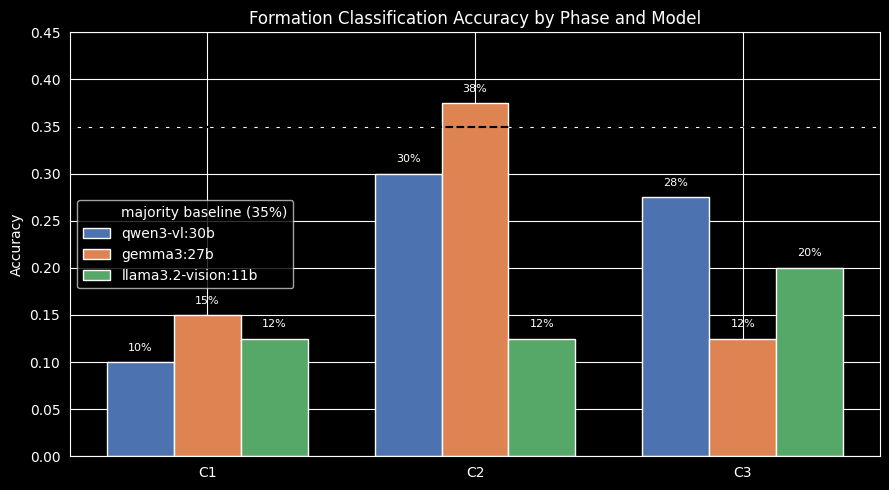

In [30]:
# Grouped bar: accuracy per phase, grouped by model
phases = PHASE_C_IDS
x = np.arange(len(phases))
width = 0.25
colors = ["#4C72B0", "#DD8452", "#55A868"]

fig, ax = plt.subplots(figsize=(9, 5))
for idx, (model, color) in enumerate(zip(MODELS, colors)):
    vals = [
        sum(r["correct"] for r in res) / len(res) if res else 0
        for res in [all_results[model].get(p, []) for p in phases]
    ]
    bars = ax.bar(x + idx * width, vals, width, label=model, color=color)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01,
                f"{v:.0%}", ha="center", va="bottom", fontsize=8)

BASELINE = 0.35  # majority-class baseline: always predict TRIO
ax.axhline(BASELINE, color="black", linestyle="--", linewidth=1.5,
           label=f"majority baseline ({BASELINE:.0%})")

ax.set_xticks(x + width)
ax.set_xticklabels(phases)
ax.set_ylim(0, 0.45)
ax.set_ylabel("Accuracy")
ax.set_title("Formation Classification Accuracy by Phase and Model")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "accuracy_by_phase_model.png", dpi=150)
plt.show()

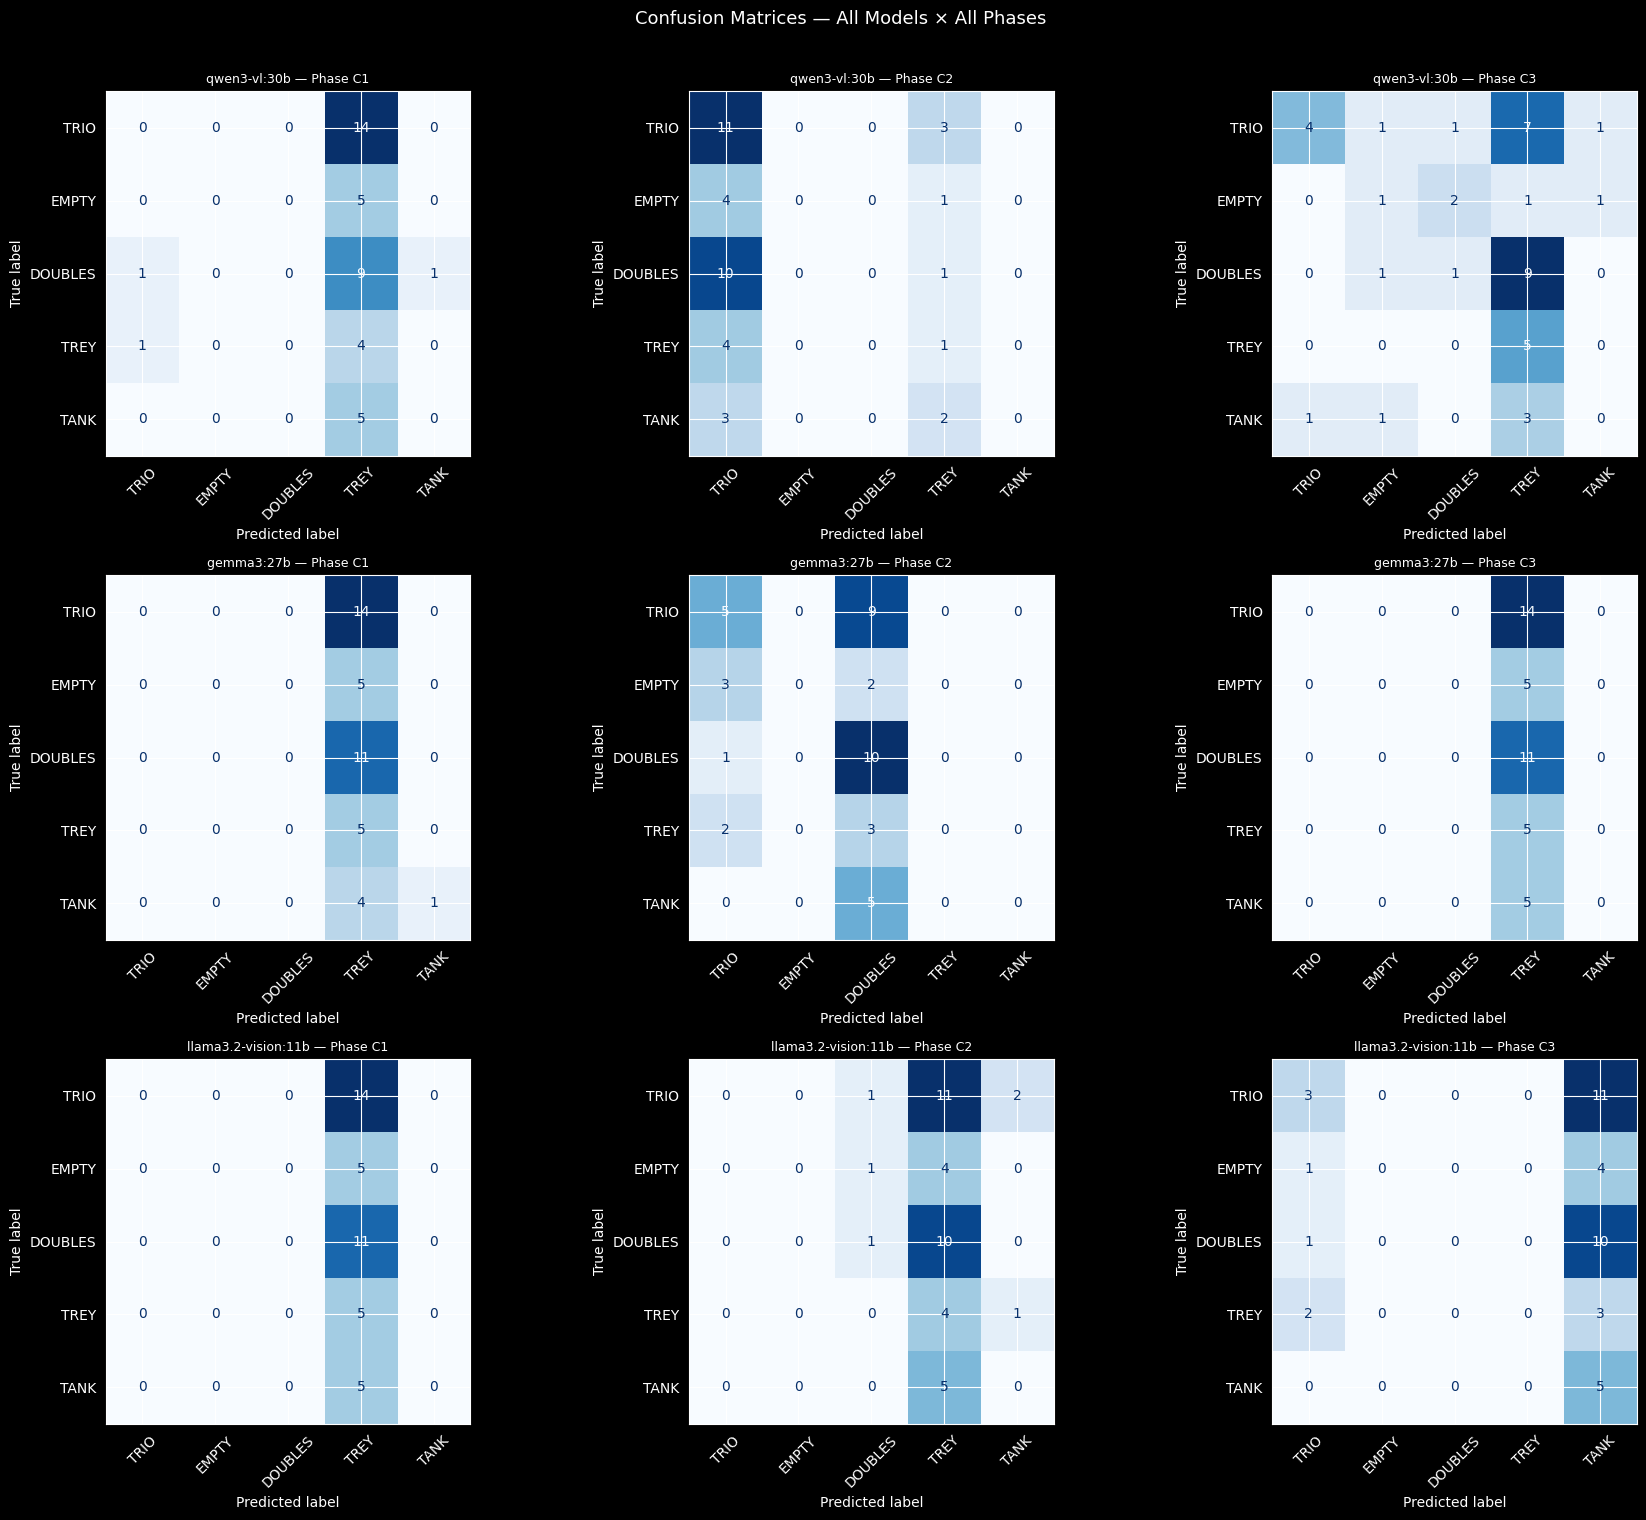

In [31]:
#  Confusion matrices: one row per model, one column per phase
fig, axes = plt.subplots(len(MODELS), len(PHASE_C_IDS), figsize=(6 * len(PHASE_C_IDS), 5 * len(MODELS)))

for row_idx, model in enumerate(MODELS):
    for col_idx, phase in enumerate(PHASE_C_IDS):
        ax = axes[row_idx][col_idx]
        results = all_results[model].get(phase, [])
        if not results:
            ax.axis("off")
            continue
        y_true = [r["ground_truth"] for r in results]
        y_pred = [r["predicted"]    for r in results]
        labels = FORMATIONS + (["UNKNOWN"] if "UNKNOWN" in y_pred else [])
        cm = confusion_matrix(y_true, y_pred, labels=labels)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
        disp.plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{model} — Phase {phase}", fontsize=9)
        ax.tick_params(axis="x", rotation=45)

plt.suptitle("Confusion Matrices — All Models × All Phases", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrices_all.png", dpi=150, bbox_inches="tight")
plt.show()

In [32]:
# Over-/under-prediction rate per formation
# Across all model x phase combinations, how often is each label the ground
# truth vs. how often is it actually predicted? A large gap indicates the
# model is not classifying so much as collapsing onto a favourite label.
from collections import Counter

gt_counter = Counter()
pred_counter = Counter()
total_preds = 0

for model in MODELS:
    for phase in PHASE_C_IDS:
        for r in all_results[model].get(phase, []):
            gt_counter[r["ground_truth"]] += 1
            pred_counter[r["predicted"]]  += 1
            total_preds += 1

over_rows = []
for f in FORMATIONS:
    gt_pct   = gt_counter[f] / total_preds
    pred_pct = pred_counter.get(f, 0) / total_preds
    over_rows.append({
        "Formation": f,
        "Ground truth %": gt_pct,
        "Predicted %": pred_pct,
        "Over-prediction ratio": pred_pct / gt_pct if gt_pct else float("nan"),
    })

over_df = pd.DataFrame(over_rows).set_index("Formation")
print(f"Across all {total_preds} Phase C predictions ({len(MODELS)} models x {len(PHASE_C_IDS)} phases x 40 images):\n")
print(over_df.to_string(formatters={
    "Ground truth %": "{:.1%}".format,
    "Predicted %": "{:.1%}".format,
    "Over-prediction ratio": "{:.1f}x".format,
}))

trey_row = over_df.loc["TREY"]
print(f"\nTREY: ground truth {trey_row['Ground truth %']:.1%} of images, "
      f"but predicted {trey_row['Predicted %']:.1%} of the time "
      f"-- a {trey_row['Over-prediction ratio']:.1f}x over-prediction rate.")

Across all 360 Phase C predictions (3 models x 3 phases x 40 images):

          Ground truth % Predicted % Over-prediction ratio
Formation                                                 
TRIO               35.0%       15.8%                  0.5x
EMPTY              12.5%        1.1%                  0.1x
DOUBLES            27.5%       10.0%                  0.4x
TREY               12.5%       61.9%                  5.0x
TANK               12.5%       11.1%                  0.9x

TREY: ground truth 12.5% of images, but predicted 61.9% of the time -- a 5.0x over-prediction rate.
